# 06 · EMT-TF expression
Overlay the most informative EMT transcription factors for this dataset. The panel is scored across the Snail / Zeb / Twist / FoxC / Prrx families and gated on detectable expression; the two most arm-specific expressed factors are shown as a categorical overlay of thresholded expressers on the grey manifold.

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..'] * 6))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)

In [3]:
# load processed data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad')); adata

### Select EMT-TFs — detection-gated, arm-specific
Score the candidate panel; keep factors expressed in >=3% of cells, then take the most arm-specific expressed TF for two *different* arms (VIM is a mesenchymal marker, not a TF, so it is excluded).

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
panel = [g for g in panel if g in adata.var_names]
X = adata[:, panel].X.toarray()
det = pd.Series((X > 0).mean(0) * 100, index = panel)
df = pd.DataFrame(X, columns = panel); df['ct'] = adata.obs.celltype.values
arm = df.groupby('ct').mean().T
arm['detect_pct'] = det
arm['spec'] = arm[['Basal','Differentiating','TSK']].max(1) / arm[['Basal','Differentiating','TSK']].sum(1)
arm['top_arm'] = arm[['Basal','Differentiating','TSK']].idxmax(1)
expressed = arm[arm.detect_pct >= 3].sort_values('detect_pct', ascending = False)
print(expressed.round(3))
# most-detected expressed TF per arm, then take two different arms
pick = expressed.sort_values('detect_pct', ascending = False).drop_duplicates('top_arm').head(2)
print('\nselected:', pick.index.tolist(), '| arms:', pick.top_arm.tolist())

ct     Differentiating  Basal    TSK  detect_pct   spec          top_arm
SNAI2            0.245  0.541  0.649      55.165  0.452              TSK
PRRX2            0.039  0.056  0.030       9.684  0.449            Basal
FOXC1            0.022  0.019  0.019       4.732  0.368  Differentiating

selected: ['SNAI2', 'PRRX2'] | arms: ['TSK', 'Basal']


In [5]:
# thresholds — a modest positive cutoff per selected gene
genes = pick.index.tolist()
cols  = ['tab:red', 'tab:blue']
g_plt = {}
for gene, c in zip(genes, cols):
    x = adata[:, gene].X.toarray().ravel()
    thr = np.quantile(x[x > 0], 0.5) if (x > 0).any() else 0.0   # median of expressers
    g_plt[gene] = (c, float(thr))
print(g_plt)

{'SNAI2': ('tab:red', 0.6908087526911453), 'PRRX2': ('tab:blue', 0.3945163489525093)}


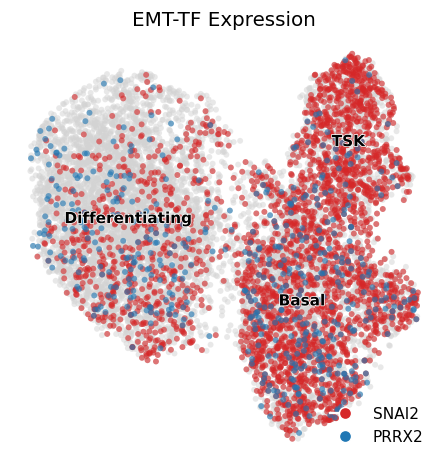

In [6]:
# save EMT-TF expression figure — categorical overlay on grey manifold
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, size = 60, alpha = .5, frameon = False, show = False, ax = ax)
for var, (c, thresh) in g_plt.items():
    sub = adata[adata[:, var].X.toarray().ravel() > thresh].copy()
    sc.pl.umap(sub, na_color = c, size = 60, alpha = .6, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=8, label=v)
           for v,(c,_) in g_plt.items()]
ax.legend(handles = handles, loc = 'lower right', frameon = False, fontsize = 10)
ax.set_title('EMT-TF Expression', size = 13)
fig.savefig(os.path.join(pth_out, 'expression.pdf'), bbox_inches = 'tight')

**SNAI2** marks the TSK / leading-edge arm (the dominant, invasion-associated EMT-TF in cSCC), while **PRRX2** marks the basal-hub / progenitor pole — two factors on opposite ends of the developmental axis. The canonical SNAI1/ZEB1/TWIST factors sit near the detection floor here.